# gate 比較與 δ 敏感度：數據整理與論文用圖

主系統只換相關判斷（gate）：JEV（full）、LLM、semantic。semantic 的 δ 是相對門檻：cosine ≥ 該子查詢最高分 − δ 的片段全部通過（ptt_v2 共 50 題、5 個題型各 10 題）。三個 gate、每個 δ 都沿用 full 那次的檢索計畫，候選片段完全相同。

資料來源：

- **完整流程**（生成器＋評審）：`src/strag_v3/eval/gate/runs/` 的評審檔（LLM gate，semantic 每個 δ 一份），JEV 是 `baseline/runs/` 的 `strag`。
- **δ 檢索掃描**（細格，不呼叫 LLM）：`python -m strag_v3.eval.gate sweep` 寫出的 `delta_retrieval_scores.csv`。

用法：

- 每張圖一個 cell，開頭的 `FIGSIZE`（英吋）直接改就能調整大小；共用的字體、字級、顏色、名稱都在下面第一個 cell。
- 圖和表存到這個 notebook 所在的 `src/strag_v3/eval/gate/result/`，檔名是各 cell 最後 `save(fig, "...")` 的字串。
- 逐題分數用專案自己的 `metrics.score_run` 算，並快取成 `gate_scores.csv`；kernel 沒裝專案套件時會直接讀這份 CSV。
- 要加新的 δ：`python -m strag_v3.eval.gate run --system semantic --delta D`，再 `judge <結果檔>`，然後重跑這個 notebook。

In [1]:
# ── 共用設定 ──────────────────────────────────────────────
import json, random, sqlite3, sys
from contextlib import closing
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "strag_v3").exists())
EVAL = ROOT / "src/strag_v3/eval"
OUT = EVAL / "gate/result"
OUT.mkdir(parents=True, exist_ok=True)

# semantic 各個 δ 的評審檔從這些資料夾找；同一個 δ 出現多次時拿較新的檔案
RUN_DIRS = [EVAL / "gate/runs"]
# 另外兩個 gate：key → (資料夾, 評審檔的樣式)，各拿最新的一份
REF_RUNS = {
    "jev": (EVAL / "baseline/runs", "*_strag*.judge.json"),
    "llm": (EVAL / "gate/runs", "*_gate_llm*.judge.json"),
}

FONT_SIZE = 9          # 全部圖的基準字級
DPI = 300              # PNG 解析度
FORMATS = ("png",)     # 要 PDF 就加 "pdf"

# 名稱
X_LABEL = "相對門檻 δ"
REFS = {"jev": "JEV gate（Ours）", "llm": "LLM gate"}          # 另外兩個 gate 的名稱（也是參考線／參考點的名稱）
SEM_NAME = "Semantic gate"                                     # 三個 gate 比較圖上會接「（δ=…）」
METRICS = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
TYPES = ["停留經驗", "移動經驗", "找地點", "找時間", "比較"]
DEFAULT_DELTA = 0.3    # 目前的預設值，圖上畫一條直的點線（列在圖例裡）；設成 None 就不畫
DEFAULT_LABEL = "預設 δ"
XLIM = (0, 0.6)        # δ 軸的範圍
XTICKS = np.arange(0, 0.61, 0.1)

# API 定價（美元／每百萬 token），2026-11 查的；換模型或調價時改這裡
#   JEV：docs.typesafe.ai/models（jev-1.14.0，只收輸入，輸出免費）
#   Claude：Anthropic 定價表（claude-haiku-5-5 是 100K token 以下的 prompt 價；claude-opus-5-5）
#   embedding：OpenAI text-embedding-3-large
PRICES = {
    "jev": {"input": 0.042, "output": 0.0},          # JEV gate
    "llm_gate": {"input": 0.10, "output": 0.50},     # LLM gate：claude-haiku-5-5
    "generator": {"input": 4.00, "output": 20.00},   # 生成器：claude-opus-5-5
    "embedding": {"input": 0.13},                    # semantic gate：text-embedding-3-large
}
EMBED_TOKENS_PER_CHAR = 1.5   # 結果檔只記了送去 embedding 的字元數，用這個比例估 token（中文一個字約 1–1.5 token）
COST_PER = 1000               # 成本圖的單位：每幾題的美元

# 顏色：P/R/F1 用色盲友善的三色；題型用 Okabe–Ito
C_MAIN, C_REF = "#0072B2", "#6b6b6b"
C_METRIC = {"precision": "#0072B2", "recall": "#E69F00", "f1": "#009E73"}
C_TYPE = dict(zip(TYPES, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9"]))
INK, MUTED, GRID = "#1a1a1a", "#6b6b6b", "#e3e3e3"
LINE_W = 1.6           # 折線粗細
MARKER = 4             # 完整流程那幾個 δ 的點大小

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "PingFang TC", "Heiti TC"],
    "font.size": FONT_SIZE, "axes.titlesize": FONT_SIZE + 1, "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE, "ytick.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a8a8a8", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.dpi": 130,
})


def save(fig, name):
    for ext in FORMATS:
        fig.savefig(OUT / f"{name}.{ext}", dpi=DPI)


def delta_axis(ax, label=True):
    # δ 軸的共同樣式，加上預設值的直線
    ax.set_xlim(*XLIM)
    ax.set_xticks(XTICKS)
    if label:
        ax.set_xlabel(X_LABEL)
    ax.grid(True)
    if DEFAULT_DELTA is not None:
        ax.axvline(DEFAULT_DELTA, color=MUTED, linestyle=":", linewidth=1.0, zorder=1,
                   label=f"{DEFAULT_LABEL}={DEFAULT_DELTA:g}")   # 有 legend 的格子會列出這一條

## 1. 載入資料

In [2]:
# 檢索掃描：每個 δ × 每題一列（`python -m strag_v3.eval.delta sweep` 產生）
retrieval = pd.read_csv(OUT / "delta_retrieval_scores.csv")
SWEEP = sorted(retrieval.delta.unique())
print(f"檢索掃描：{len(SWEEP)} 個 δ（{SWEEP[0]:g}–{SWEEP[-1]:g}）× {retrieval.id.nunique()} 題")

檢索掃描：31 個 δ（0–0.6）× 50 題


In [3]:
# 完整流程：每份評審檔 × 每題一列
SCORES_CSV = OUT / "gate_scores.csv"


def judge_files() -> dict:
    # (gate, δ) → 評審檔。semantic 每個 δ 一份；jev、llm 的 δ 是 NaN。
    picked = {}
    for folder in RUN_DIRS:
        for jp in sorted(folder.glob("*.judge.json")):
            gate = json.loads(jp.read_text())["run_config"].get("gate") or {}
            if gate.get("name") == "semantic":
                picked[("semantic", float(gate["delta"]))] = jp
    for key, (folder, pattern) in REF_RUNS.items():
        if found := sorted(folder.glob(pattern)):
            picked[(key, float("nan"))] = found[-1]
    return picked


def compute_scores() -> pd.DataFrame:
    for p in (str(ROOT), str(ROOT / "src")):
        if p not in sys.path:
            sys.path.insert(0, p)
    from strag_v3.eval.baseline.fragments import load_fragments
    from strag_v3.eval.baseline.judge import Verdict
    from strag_v3.eval.baseline.metrics import score_run
    from strag_v3.eval.baseline.questions import load_questions
    from strag_v3.eval.baseline.results import load_judge, load_run

    questions = load_questions()
    with closing(sqlite3.connect(f"file:{ROOT / 'data/ptt.db'}?mode=ro", uri=True)) as conn:
        fragments = load_fragments(conn)
    rows = []
    for (gate, delta), jp in judge_files().items():
        data, run_path = load_judge(jp)
        config, outcomes = load_run(run_path)
        verdicts = [Verdict(**v) for v in data["questions"]]
        passed = {o.id: len(set(o.contents)) for o in outcomes}
        extra = {o.id: o.extra.get("gate") or {} for o in outcomes}   # LLM gate 的 token、semantic 的 embedding 字元數
        for s in score_run(questions, outcomes, verdicts, fragments, config["retrieval"]):
            g = extra.get(s.id, {})
            rows.append({"gate": gate, "delta": delta, "run": run_path.name, **asdict(s), "passed": passed.get(s.id, 0),
                         "gate_input_tokens": g.get("input_tokens", 0), "gate_output_tokens": g.get("output_tokens", 0),
                         "gate_cli_usd": g.get("cost_usd", 0.0), "embed_chars": g.get("embed_chars", 0)})
    return pd.DataFrame(rows)


try:
    scores = compute_scores()
    scores.to_csv(SCORES_CSV, index=False)
    print(f"重新計算，已寫入 {SCORES_CSV.relative_to(ROOT)}")
except ImportError as e:
    scores = pd.read_csv(SCORES_CSV)
    print(f"kernel 缺專案套件（{e.name}），改讀 {SCORES_CSV.relative_to(ROOT)}")

# 有題目出錯的結果檔（例如撞到用量上限）不列入，先用 `run --retry` 補跑
bad = scores.groupby("run").error.sum()
bad = bad[bad > 0]
if len(bad):
    print("略過有出錯題的結果檔：" + "、".join(f"{r}（{n} 題）" for r, n in bad.items()))
    scores = scores[~scores.run.isin(bad.index)]

# JEV gate 的 token：full 的結果檔沒記，用 `python -m strag_v3.eval.gate jev-usage` 重問 JEV 量到的
jev_usage = pd.read_csv(OUT / "jev_gate_usage.csv").set_index("id")
is_jev = scores.gate == "jev"
scores.loc[is_jev, "gate_input_tokens"] = scores.loc[is_jev, "id"].map(jev_usage.input_tokens).values
scores.loc[is_jev, "gate_output_tokens"] = scores.loc[is_jev, "id"].map(jev_usage.output_tokens).values

# 每題的美元成本：gate（JEV／LLM 照 token，semantic 照 embedding 字元數估）和生成器輸入
M = 1e6
gate_price = scores.gate.map({"jev": PRICES["jev"], "llm": PRICES["llm_gate"]})
scores["gate_usd"] = [
    (r.gate_input_tokens * p["input"] + r.gate_output_tokens * p["output"]) / M if isinstance(p, dict)
    else r.embed_chars * EMBED_TOKENS_PER_CHAR * PRICES["embedding"]["input"] / M
    for r, p in zip(scores.itertuples(), gate_price)]
scores["generator_input_usd"] = scores.input_tokens * PRICES["generator"]["input"] / M
scores["total_usd"] = scores.gate_usd + scores.generator_input_usd
scores.to_csv(SCORES_CSV, index=False)

sem_scores = scores[scores.gate == "semantic"]
E2E = sorted(sem_scores.delta.unique())          # 跑過完整流程的 δ
print("完整流程的 δ：", "、".join(f"{d:g}" for d in E2E))
scores.groupby(["gate", "delta", "run"], dropna=False).agg(題數=("id", "size"), 出錯=("error", "sum")).reset_index()

重新計算，已寫入 src/strag_v3/eval/gate/result/gate_scores.csv
完整流程的 δ： 0、0.05、0.1、0.15、0.2、0.25、0.3、0.4


,gate,delta,run,題數,出錯
0,jev,NaN,20261110-191250_strag.json,50,0
1,llm,NaN,20261111-113558_gate_llm.json,50,0
2,semantic,0.00,20261111-130938_gate_semantic.json,50,0
3,semantic,0.05,20261111-130045_gate_semantic.json,50,0
4,semantic,0.10,20261111-121330_gate_semantic.json,50,0
5,semantic,0.15,20261111-121750_gate_semantic.json,50,0
6,semantic,0.20,20261111-121544_gate_semantic.json,50,0
7,semantic,0.25,20261111-130801_gate_semantic.json,50,0
8,semantic,0.30,20261111-113057_gate_semantic.json,50,0
9,semantic,0.40,20261111-130435_gate_semantic.json,50,0


## 2. 彙總表

答案層兩項附 95% 信賴區間（逐題 bootstrap 10,000 次，固定種子，各組重抽到同樣的題目）。

In [4]:
def bootstrap_ci(xs, seed=20261110, rounds=10_000):
    # 跟 metrics.bootstrap_ci 同一個演算法與種子
    xs = list(xs)
    rng, n = random.Random(seed), len(xs)
    means = sorted(sum(xs[rng.randrange(n)] for _ in range(n)) / n for _ in range(rounds))
    return means[int(0.025 * rounds)], means[int(0.975 * rounds) - 1]


def summarize(df: pd.DataFrame, ci=True) -> pd.Series:
    cov, uns = df.coverage.astype(float), df.unsupported.astype(float)
    out = {"n": len(df), "coverage": cov.mean(), "unsupported": uns.mean()}
    if ci:
        out["coverage_lo"], out["coverage_hi"] = bootstrap_ci(cov)
        out["unsupported_lo"], out["unsupported_hi"] = bootstrap_ci(uns)
    for m in ("article_recall", "precision", "recall", "f1", "passed", "input_tokens"):
        out[m] = df[m].mean()
    retrieved = df.retrieved.sum()
    out["violation_rate"] = df.violations.sum() / retrieved if retrieved else 0.0
    for m in ("error", "empty"):
        out[m] = int(df[m].sum())
    # gate 自己的模型呼叫數：JEV 呼叫，加上扣掉規劃器、生成器各 1 次後的 LLM 呼叫；semantic 只做 embedding，是 0
    out["gate_calls"] = (df.jev_calls + df.llm_calls - 2).mean()
    for m in ("gate_input_tokens", "gate_output_tokens", "embed_chars", "gate_cli_usd", "gate_usd",
              "generator_input_usd", "total_usd"):
        out[m] = df[m].mean()
    return pd.Series(out)


# 完整流程：semantic 各個 δ 一列（index 是 δ），參考的 gate 各一列（index 是 jev／llm）
e2e = pd.DataFrame({d: summarize(sem_scores[sem_scores.delta == d]) for d in E2E}).T.rename_axis("delta")
ref = pd.DataFrame({k: summarize(scores[scores.gate == k]) for k in REFS if (scores.gate == k).any()}).T
pd.concat([e2e.rename(index=lambda d: f"semantic δ={d:g}"), ref.rename(index=REFS)]).to_csv(
    OUT / "gate_summary.csv", index_label="gate")

# 檢索掃描：每個 δ 的平均、依題型的平均
RET_COLS = ["passed", "candidates", "article_recall", "precision", "recall", "f1"]
ret = retrieval.groupby("delta")[RET_COLS].mean()
ret_type = retrieval.groupby(["delta", "type"])[RET_COLS].mean()
ret.to_csv(OUT / "delta_retrieval_summary.csv")
ret_type.to_csv(OUT / "delta_retrieval_by_type.csv")

# 兩種來源在同一個 δ 上的檢索指標應該一樣（候選片段相同、門檻相同）
gap = (e2e[["precision", "recall", "f1"]].astype(float) - ret.reindex(E2E)[["precision", "recall", "f1"]]).abs().max().max()
print(f"完整流程 vs 檢索掃描，同一個 δ 的 P/R/F1 最大差距：{gap:.4f}")

BEST = float(ret.f1.idxmax())      # 片段 F1 最高的 δ
print(f"片段 F1 最高：δ={BEST:g}（F1={ret.f1.max():.3f}）")

fmt_ci = lambda r, m: f"{r[m]:.3f} [{r[m + '_lo']:.3f}, {r[m + '_hi']:.3f}]"
both = pd.concat([e2e.rename(index=lambda d: f"semantic（δ={d:g}）"), ref.rename(index=REFS)])
main_table = pd.DataFrame({
    "expect 覆蓋率 [95% CI]": both.apply(fmt_ci, axis=1, m="coverage"),
    "無支持比例 [95% CI]": both.apply(fmt_ci, axis=1, m="unsupported"),
    "文章 recall": both.article_recall.map("{:.3f}".format),
    "片段 P": both.precision.map("{:.3f}".format), "片段 R": both.recall.map("{:.3f}".format),
    "片段 F1": both.f1.map("{:.3f}".format),
    "通過片段／題": both.passed.map("{:.1f}".format),
    "輸入 token／題": both.input_tokens.map("{:.0f}".format),
    "出錯": both.error.astype(int), "取回為空": both["empty"].astype(int),
}).rename_axis("gate")
main_table.to_csv(OUT / "gate_main_table.csv")
main_table

完整流程 vs 檢索掃描，同一個 δ 的 P/R/F1 最大差距：0.0000
片段 F1 最高：δ=0.12（F1=0.781）


,expect 覆蓋率 [95% CI],無支持比例 [95% CI],文章 recall,片段 P,片段 R,片段 F1,通過片段／題,輸入 token／題,出錯,取回為空
gate,,,,,,,,,,
semantic（δ=0）,"0.430 [0.349, 0.515]","0.100 [0.020, 0.200]",0.488,0.840,0.383,0.500,1.2,2389,0,0
semantic（δ=0.05）,"0.620 [0.531, 0.707]","0.220 [0.120, 0.340]",0.643,0.853,0.573,0.653,2.4,2810,0,0
semantic（δ=0.1）,"0.757 [0.681, 0.831]","0.460 [0.320, 0.600]",0.823,0.833,0.752,0.749,3.8,3140,0,0
semantic（δ=0.15）,"0.877 [0.809, 0.936]","0.540 [0.400, 0.680]",0.892,0.766,0.879,0.783,4.9,3827,0,0
semantic（δ=0.2）,"0.881 [0.809, 0.941]","0.560 [0.420, 0.700]",0.923,0.696,0.909,0.747,6.2,3778,0,0
semantic（δ=0.25）,"0.953 [0.897, 0.992]","0.580 [0.440, 0.720]",0.990,0.629,0.986,0.731,7.8,4056,0,0
semantic（δ=0.3）,"0.974 [0.941, 0.997]","0.680 [0.540, 0.800]",0.990,0.596,0.986,0.701,8.5,4110,0,0
semantic（δ=0.4）,"0.991 [0.981, 1.000]","0.640 [0.500, 0.760]",1.000,0.576,1.000,0.688,9.0,4798,0,0
JEV gate（Ours）,"0.988 [0.971, 1.000]","0.580 [0.440, 0.720]",1.000,0.757,1.000,0.837,6.2,3803,0,0


## 圖 1　三個 gate 的片段級 Precision／Recall／F1

semantic 用 `COMPARE_DELTA` 那個 δ（預設就是系統的預設值）。`COMPARE_METRICS` 決定畫哪些指標和順序，`COMPARE_GATES` 決定 gate 的順序。

,precision,recall,f1
gate,,,
JEV gate（Ours）,0.757,1.000,0.837
LLM gate,0.748,0.990,0.830
Semantic gate（δ=0.3）,0.596,0.986,0.701


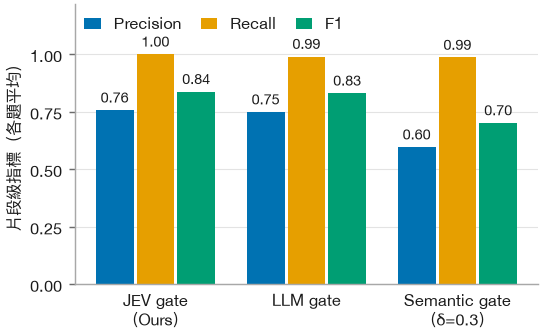

In [5]:
FIGSIZE = (4.6, 2.8)
COMPARE_DELTA = DEFAULT_DELTA if DEFAULT_DELTA is not None else E2E[-1]
COMPARE_GATES = ["jev", "llm", "semantic"]
COMPARE_METRICS = ["precision", "recall", "f1"]
BAR_W = 0.25

rows = {**{k: ref.loc[k] for k in REFS if k in ref.index}, "semantic": e2e.loc[COMPARE_DELTA]}
names = {**REFS, "semantic": f"{SEM_NAME}（δ={COMPARE_DELTA:g}）"}
gates = [g for g in COMPARE_GATES if g in rows]
compare = pd.DataFrame({g: rows[g] for g in gates}).T
compare.insert(0, "gate", [names[g] for g in gates])
compare.to_csv(OUT / "gate_compare.csv", index_label="key")

x = np.arange(len(gates))
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, m in enumerate(COMPARE_METRICS):
    v = compare[m].astype(float).values
    xs = x + (i - (len(COMPARE_METRICS) - 1) / 2) * (BAR_W + 0.02)
    ax.bar(xs, v, width=BAR_W, color=C_METRIC[m], label=METRICS[m])
    for xi, vi in zip(xs, v):
        ax.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", va="bottom", fontsize=FONT_SIZE - 1)
ax.set(ylim=(0, 1.22), ylabel="片段級指標（各題平均）")
ax.set_xticks(x, [names[g].replace("（", "\n（") for g in gates])
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.grid(axis="y")
ax.tick_params(axis="x", length=0)
ax.legend(ncols=len(COMPARE_METRICS), frameon=False, loc="upper left", handlelength=1, columnspacing=1.2, borderaxespad=0.2)
save(fig, "gate_compare")
compare[["gate", *COMPARE_METRICS]].set_index("gate").astype(float).round(3)

## 圖 2　不同 gate 的成本（美元）

每 `COST_PER` 題的美元，照第一個 cell 的 `PRICES`（API 定價）乘上實際的 token 數。semantic 只挑 `COST_DELTAS` 這幾個 δ（要跑過完整流程的）。

- **gate 判斷成本**：JEV 是輸入 token（輸出免費）；LLM gate 是輸入加輸出 token；semantic 是 embedding（只記了字元數，用 `EMBED_TOKENS_PER_CHAR` 估 token）。
- **生成器輸入成本**：通過 gate 的片段越多，交給生成器的 prompt 越長。
- **合計**：上面兩項相加。生成器的輸出 token 結果檔沒有記，所以沒算進去（各組都少這一塊）；規劃器三組共用同一份計畫，也不算。

`COST_PANELS` 可以換成其他欄位，例如 `gate_calls`（gate 的模型呼叫數）、`passed`（通過片段數）、`input_tokens`（生成器輸入 token）、`gate_input_tokens`、`gate_output_tokens`。

,gate_calls,gate_input_tokens,gate_output_tokens,embed_chars,passed,input_tokens,gate_usd,generator_input_usd,total_usd,gate_cli_usd
gate,,,,,,,,,,
JEV gate（Ours）,9.52,4202.92,209.44,0.00,6.24,3803.42,0.18,15.21,15.39,0.00
LLM gate,9.52,12443.24,1944.20,0.00,6.10,4197.84,2.22,16.79,19.01,2.44
Semantic gate（δ=0.1）,0.00,0.00,0.00,576.82,3.76,3140.16,0.11,12.56,12.67,0.00
Semantic gate（δ=0.2）,0.00,0.00,0.00,576.82,6.22,3778.50,0.11,15.11,15.23,0.00
Semantic gate（δ=0.3）,0.00,0.00,0.00,576.82,8.54,4110.50,0.11,16.44,16.55,0.00
Semantic gate（δ=0.4）,0.00,0.00,0.00,576.82,9.00,4797.50,0.11,19.19,19.30,0.00


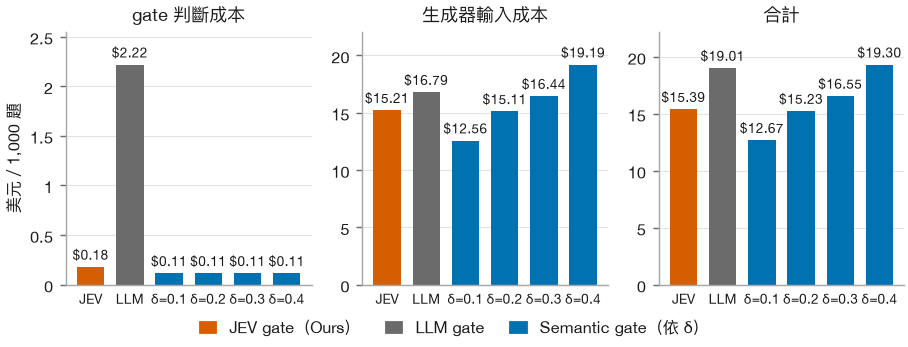

In [6]:
FIGSIZE = (7.2, 2.6)
COST_DELTAS = [0.1, 0.2, 0.3, 0.4]
USD = "${:,.2f}"
COST_PANELS = [("gate_usd", "gate 判斷成本", USD), ("generator_input_usd", "生成器輸入成本", USD), ("total_usd", "合計", USD)]
USD_COLS = {"gate_usd", "generator_input_usd", "total_usd", "gate_cli_usd"}   # 這些欄位會乘上 COST_PER
COST_TABLE = ["gate_calls", "gate_input_tokens", "gate_output_tokens", "embed_chars", "passed", "input_tokens",
              "gate_usd", "generator_input_usd", "total_usd", "gate_cli_usd"]   # 另存 CSV 的欄位（每題平均，美元不乘 COST_PER）
C_GATE = {"jev": "#D55E00", "llm": "#6b6b6b", "semantic": C_MAIN}
TICKS = {"jev": "JEV", "llm": "LLM"}      # x 軸上的短名稱；semantic 的柱子標 δ=…，顏色看圖例
BAR_W = 0.7

# 每根柱子：(key, 完整名稱, x 軸標籤, 顏色, 數值)
bars = [(k, REFS[k], TICKS[k], C_GATE[k], ref.loc[k]) for k in REFS if k in ref.index]
bars += [(f"semantic_{d:g}", f"{SEM_NAME}（δ={d:g}）", f"δ={d:g}", C_GATE["semantic"], e2e.loc[d])
         for d in COST_DELTAS if d in e2e.index]
cost = pd.DataFrame({b[0]: b[4][COST_TABLE] for b in bars}).T.astype(float)
cost.insert(0, "gate", [b[1] for b in bars])
cost.to_csv(OUT / "gate_cost.csv", index_label="key")

x = np.arange(len(bars))
fig, axes = plt.subplots(1, len(COST_PANELS), figsize=FIGSIZE, squeeze=False)
for ax, (m, title, fmt) in zip(axes[0], COST_PANELS):
    v = cost[m].values * (COST_PER if m in USD_COLS else 1)
    ax.bar(x, v, width=BAR_W, color=[b[3] for b in bars])
    for xi, vi in zip(x, v):
        ax.text(xi, vi + v.max() * 0.02, fmt.format(vi), ha="center", va="bottom", fontsize=FONT_SIZE - 1.5)
    ax.set(ylim=(0, v.max() * 1.15), title=title + ("" if m in USD_COLS else "／題"))
    ax.set_xticks(x, [b[2] for b in bars], fontsize=FONT_SIZE - 1.5)
    ax.yaxis.set_major_formatter(lambda t, _: f"{t:,g}")
    ax.grid(axis="y")
    ax.tick_params(axis="x", length=0)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_GATE[k]) for k in ("jev", "llm", "semantic")],
           labels=[REFS["jev"], REFS["llm"], f"{SEM_NAME}（依 δ）"], ncols=3, frameon=False,
           loc="lower center", bbox_to_anchor=(0.5, -0.08), handlelength=1, columnspacing=1.6)
if all(m in USD_COLS for m, _, _ in COST_PANELS):
    axes[0][0].set_ylabel(f"美元／{COST_PER:,} 題")
fig.tight_layout(w_pad=1.2)
save(fig, "gate_cost")
show = cost.set_index("gate")
show[[c for c in show.columns if c in USD_COLS]] *= COST_PER
show.round(2)

## 圖 3　片段級檢索品質對 δ

檢索掃描的細格。橫的虛線是 JEV gate 的同一個指標（`REF_METRICS` 決定畫哪幾條），圓點是 F1 最高的 δ。

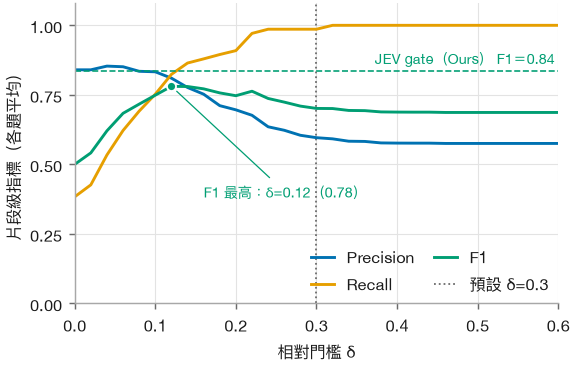

In [7]:
FIGSIZE = (4.8, 3.0)
REF_METRICS = ("f1",)          # 哪些指標畫 JEV 的參考線，例如 ("precision", "recall", "f1")
YLIM = (0, 1.08)
BEST_NOTE = (0.16, 0.40)       # 「F1 最高」那行字的位置（資料座標）；設成 None 就不標

fig, ax = plt.subplots(figsize=FIGSIZE)
for m, name in METRICS.items():
    ax.plot(ret.index, ret[m], color=C_METRIC[m], linewidth=LINE_W, label=name)
for m in REF_METRICS:
    if "jev" in ref.index:
        ax.axhline(ref.loc["jev", m], color=C_METRIC[m], linestyle="--", linewidth=0.9)
        ax.annotate(f"{REFS['jev']} {METRICS[m]}＝{ref.loc['jev', m]:.2f}", (XLIM[1], ref.loc["jev", m]),
                    xytext=(-2, 2), textcoords="offset points", ha="right", va="bottom",
                    fontsize=FONT_SIZE - 1, color=C_METRIC[m])
ax.plot(BEST, ret.f1[BEST], "o", color=C_METRIC["f1"], markersize=MARKER + 1, markeredgecolor="white", zorder=4)
if BEST_NOTE is not None:
    ax.annotate(f"F1 最高：δ={BEST:g}（{ret.f1[BEST]:.2f}）", (BEST, ret.f1[BEST]), xytext=BEST_NOTE,
                ha="left", va="center", fontsize=FONT_SIZE - 1, color=C_METRIC["f1"],
                arrowprops={"arrowstyle": "-", "color": C_METRIC["f1"], "linewidth": 0.7, "shrinkB": 4})
delta_axis(ax)
ax.set(ylim=YLIM, ylabel="片段級指標（各題平均）")
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.legend(ncols=2, frameon=False, loc="lower right", handlelength=1.4, columnspacing=1.2, borderaxespad=0.2)
save(fig, "delta_retrieval")

## 圖 4　Precision–Recall 軌跡

δ 由小到大沿著線往右下走；`LABEL_DELTAS` 是要標出來的 δ，`OFFSETS` 調整標籤位置（單位：點）。另外兩個 gate 各是一個點。

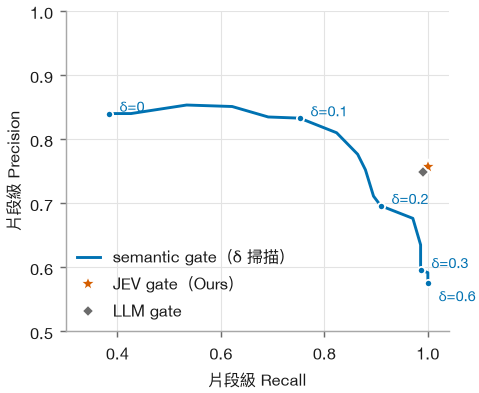

In [8]:
FIGSIZE = (3.8, 3.2)
LABEL_DELTAS = [0.0, 0.1, 0.2, 0.3, 0.6]
OFFSETS = {0.6: (6, -7)}        # δ → (dx, dy)；沒寫的用 DEFAULT_OFFSET
DEFAULT_OFFSET = (6, 4)
REF_MARKERS = {"jev": "*", "llm": "D"}
XLIM_PR, YLIM_PR = (0.3, 1.04), (0.5, 1.0)

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(ret.recall, ret.precision, color=C_MAIN, linewidth=LINE_W, label="semantic gate（δ 掃描）", zorder=2)
for d in LABEL_DELTAS:
    if d in ret.index:
        ax.plot(ret.recall[d], ret.precision[d], "o", color=C_MAIN, markersize=MARKER, markeredgecolor="white", zorder=3)
        dx, dy = OFFSETS.get(d, DEFAULT_OFFSET)
        ax.annotate(f"δ={d:g}", (ret.recall[d], ret.precision[d]), xytext=(dx, dy), textcoords="offset points",
                    ha="left" if dx >= 0 else "right", va="center", fontsize=FONT_SIZE - 1, color=C_MAIN)
for k, marker in REF_MARKERS.items():
    if k in ref.index:
        ax.plot(ref.loc[k, "recall"], ref.loc[k, "precision"], marker, color="#D55E00" if k == "jev" else C_REF,
                markersize=MARKER + (5 if marker == "*" else 1), markeredgecolor="white", linestyle="none",
                label=REFS[k], zorder=4)
ax.set(xlim=XLIM_PR, ylim=YLIM_PR, xlabel="片段級 Recall", ylabel="片段級 Precision")
ax.grid(True)
ax.legend(frameon=False, loc="lower left", handlelength=1.4, borderaxespad=0.3)
save(fig, "delta_pr_curve")

## 圖 5　答案品質對 δ

完整流程的幾個 δ（點），色帶是 95% 信賴區間；橫的虛線是 JEV gate。

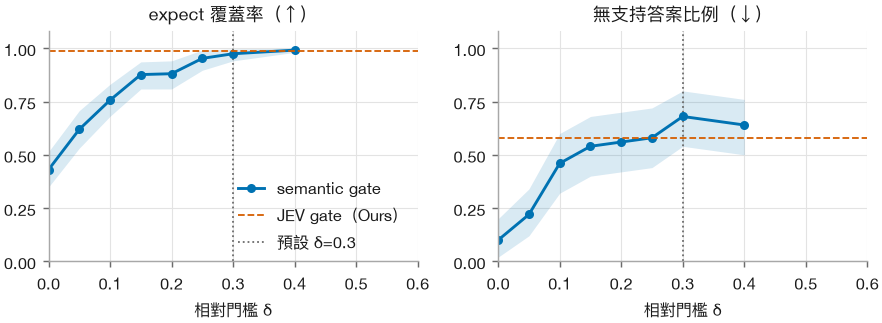

In [9]:
FIGSIZE = (7.0, 2.7)
PANELS = [("coverage", "expect 覆蓋率（↑）", (0, 1.08)), ("unsupported", "無支持答案比例（↓）", (0, 1.08))]

fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, squeeze=False)
x = np.array(E2E)
for ax, (m, title, ylim) in zip(axes[0], PANELS):
    v, lo, hi = (e2e[c].astype(float).values for c in (m, m + "_lo", m + "_hi"))
    ax.fill_between(x, lo, hi, color=C_MAIN, alpha=0.15, linewidth=0)
    ax.plot(x, v, "-o", color=C_MAIN, linewidth=LINE_W, markersize=MARKER, label="semantic gate")
    if "jev" in ref.index:
        ax.axhline(ref.loc["jev", m], color="#D55E00", linestyle="--", linewidth=1.0, label=REFS["jev"])
    delta_axis(ax)
    ax.set(ylim=ylim, title=title)
    ax.set_yticks(np.arange(0, 1.01, 0.25))
axes[0][0].legend(frameon=False, loc="lower right", handlelength=1.6, borderaxespad=0.2)
fig.tight_layout(w_pad=1.5)
save(fig, "delta_answer")

## 圖 6　依題型

檢索掃描的細格，每個題型一條線。`BY_TYPE_METRIC` 可以換成 `precision`、`recall`、`f1`、`passed`。

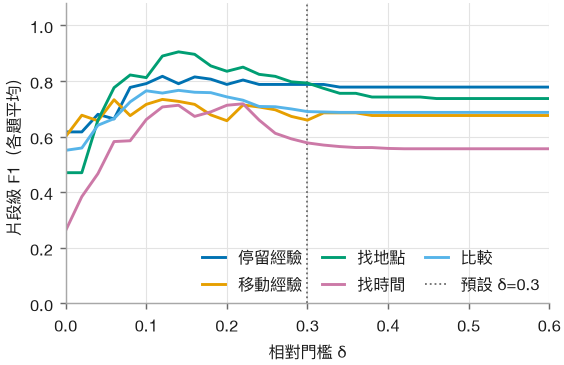

In [10]:
FIGSIZE = (4.8, 3.0)
BY_TYPE_METRIC, BY_TYPE_LABEL = "f1", "片段級 F1（各題平均）"
YLIM = (0, 1.08)

fig, ax = plt.subplots(figsize=FIGSIZE)
tbl = ret_type[BY_TYPE_METRIC].unstack("type")[TYPES]
for t in TYPES:
    ax.plot(tbl.index, tbl[t], color=C_TYPE[t], linewidth=LINE_W, label=t)
delta_axis(ax)
ax.set(ylim=YLIM, ylabel=BY_TYPE_LABEL)
ax.legend(ncols=3, frameon=False, loc="lower right", handlelength=1.4, columnspacing=1.2, borderaxespad=0.2)
save(fig, "delta_by_type")

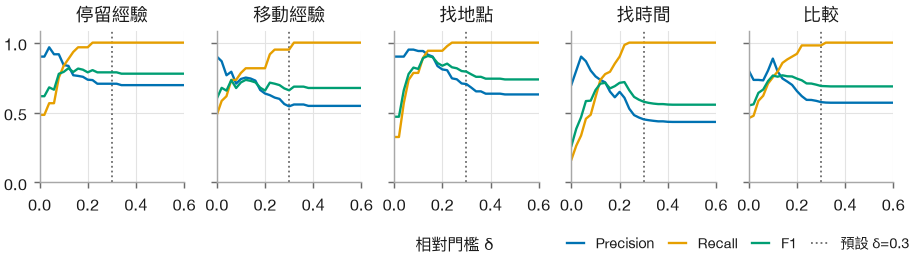

In [11]:
# 同樣依題型，一個題型一格，每格畫 P/R/F1
FIGSIZE = (7.2, 2.1)

fig, axes = plt.subplots(1, len(TYPES), figsize=FIGSIZE, sharey=True)
for ax, t in zip(axes, TYPES):
    sub = ret_type.xs(t, level="type")
    for m, name in METRICS.items():
        ax.plot(sub.index, sub[m], color=C_METRIC[m], linewidth=LINE_W - 0.3, label=name)
    delta_axis(ax, label=False)
    ax.set_xticks(XTICKS[::2])
    ax.set(ylim=(0, 1.08), title=t)
    ax.set_yticks(np.arange(0, 1.01, 0.5))
fig.tight_layout(w_pad=0.6, rect=(0, 0.1, 1, 1))
fig.supxlabel(X_LABEL, fontsize=FONT_SIZE, y=0.02)
fig.legend(*axes[0].get_legend_handles_labels(), ncols=4, frameon=False, loc="lower right",
           bbox_to_anchor=(1.0, -0.02), handlelength=1.2, columnspacing=1.0, fontsize=FONT_SIZE - 1)
save(fig, "delta_by_type_prf")

## 圖 7　通過片段數與生成器成本對 δ

左：每題通過 gate 的片段數（檢索掃描）；灰色虛線是候選片段數（各子查詢加總，比較題的兩個子查詢撈到同一個片段會重複算，所以通過數追不到這條線）。右：每題交給生成器的輸入 token（完整流程）。橘色虛線是 JEV gate。

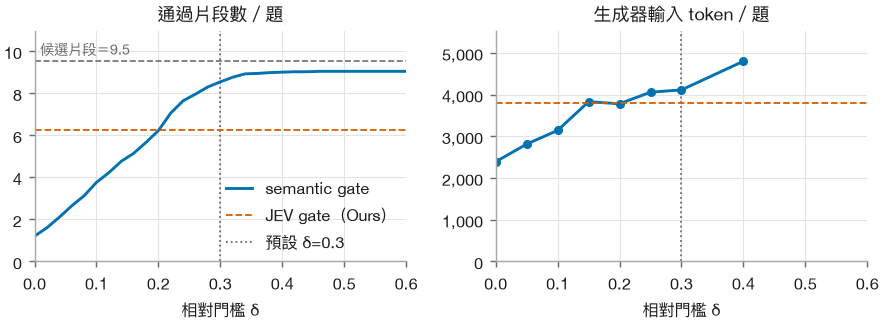

In [12]:
FIGSIZE = (7.0, 2.7)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=FIGSIZE)
ax.plot(ret.index, ret.passed, color=C_MAIN, linewidth=LINE_W, label="semantic gate")
cand = ret.candidates.iloc[0]
ax.axhline(cand, color=C_REF, linestyle="--", linewidth=0.9)
ax.annotate(f"候選片段＝{cand:.1f}", (XLIM[0], cand), xytext=(3, 2), textcoords="offset points",
            ha="left", va="bottom", fontsize=FONT_SIZE - 1, color=C_REF)
if "jev" in ref.index:
    ax.axhline(ref.loc["jev", "passed"], color="#D55E00", linestyle="--", linewidth=1.0, label=REFS["jev"])
delta_axis(ax)
ax.set(ylim=(0, cand * 1.15), title="通過片段數／題")
ax.legend(frameon=False, loc="lower right", handlelength=1.6, borderaxespad=0.2)

ax2.plot(E2E, e2e.input_tokens.astype(float), "-o", color=C_MAIN, linewidth=LINE_W, markersize=MARKER)
if "jev" in ref.index:
    ax2.axhline(ref.loc["jev", "input_tokens"], color="#D55E00", linestyle="--", linewidth=1.0)
delta_axis(ax2)
ax2.set(ylim=(0, max(e2e.input_tokens.max(), ref.input_tokens.max() if len(ref) else 0) * 1.15), title="生成器輸入 token／題")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
fig.tight_layout(w_pad=1.5)
save(fig, "delta_cost")

## 表　檢索掃描（每 0.1 一列）

In [13]:
ret.loc[[d for d in ret.index if abs(d * 10 - round(d * 10)) < 1e-9]].round(3)

,passed,candidates,article_recall,precision,recall,f1
delta,,,,,,
0.0,1.20,9.52,0.488,0.840,0.383,0.500
0.1,3.76,9.52,0.823,0.833,0.752,0.749
0.2,6.22,9.52,0.923,0.696,0.909,0.747
0.3,8.54,9.52,0.990,0.596,0.986,0.701
0.4,9.00,9.52,1.000,0.576,1.000,0.688
0.5,9.04,9.52,1.000,0.575,1.000,0.687
0.6,9.04,9.52,1.000,0.575,1.000,0.687
